# 02 - Resolution at the top: test structure, measurement error, version equating

Inputs: equating tables (2020-2026), math scoring schemes (`data/raw/math_tests`),
admitted students 2026.

In [1]:
from common import *
import re
from pypdf import PdfReader
from load import load_equating, load_admissions

eq = load_equating()
math = eq[eq.subject == "MATH"].copy()

## 1. Structure of the mathematics test (from the official scoring schemes)
Open-ended items are marked "(k) item." in the scheme, k = maximum points. All earlier items are
4-option multiple-choice items worth 1 point.

In [2]:
rows = []
for f in sorted((ROOT / "data/raw/math_tests").glob("math_*_scheme_v[12].pdf")):
    text = "\n".join(p.extract_text() for p in PdfReader(f).pages)
    opens = [(int(n), int(k)) for k, n in re.findall(r"\((\d)\)\s*(\d{1,2})\s*\.", text)]
    first = min(n for n, _ in opens)
    rows.append({"year": int(f.stem.split("_")[1]), "version": f.stem.split("_")[-1], "n_mc": first - 1,
                 "n_open": len(opens), "open_points": "+".join(str(k) for _, k in opens),
                 "open_total": sum(k for _, k in opens), "max": first - 1 + sum(k for _, k in opens),
                 "sum_k2": first - 1 + sum(k * k for _, k in opens)})
struct = pd.DataFrame(rows)
assert (struct["max"] == 51).all()
struct.to_csv(OUT / "t02_math_test_structure.csv", index=False)
struct

,year,version,n_mc,n_open,open_points,open_total,max,sum_k2
0,2021,v1,27,8,2+2+3+3+3+3+4+4,24,51,103
1,2021,v2,27,8,2+2+3+3+3+3+4+4,24,51,103
2,2022,v1,27,8,2+2+3+3+3+3+4+4,24,51,103
3,2022,v2,27,8,2+2+3+3+3+3+4+4,24,51,103
4,2023,v1,37,4,3+3+4+4,14,51,87
5,2023,v2,37,4,3+3+4+4,14,51,87
6,2024,v1,37,4,3+3+4+4,14,51,87
7,2024,v2,37,4,3+3+4+4,14,51,87
8,2025,v1,37,4,3+3+4+4,14,51,87
9,2025,v2,37,4,3+3+4+4,14,51,87


## 2. Conditional standard error of measurement (SEM) near the top
Binomial error model (Lord 1965): for a student whose true proportion of points is p, the raw score
is the sum of item scores, each scored independently. Two bounds for the open items:
- lower: an open item worth k points behaves like k independent 1-point items -> Var = 51 p(1-p)
- upper: an open item is all-or-nothing (k points or 0) -> Var = (n_mc + sum k^2) p(1-p)
Items of unequal difficulty make the true SEM somewhat smaller than the equal-difficulty value,
so these are approximations; the simulation in notebook 04 therefore also uses 0.5x and 0.75x.

In [3]:
sk2 = struct.drop_duplicates("year").set_index("year")["sum_k2"]
true_scores = np.arange(40, 51.5, 1.0)
sem = pd.DataFrame({"true_raw": true_scores})
sem["sem_lower"] = np.sqrt(51 * (true_scores / 51) * (1 - true_scores / 51))
for y, k2 in [(2022, sk2[2022]), (2026, sk2[2026])]:
    sem[f"sem_upper_{y}fmt"] = np.sqrt(k2 * (true_scores / 51) * (1 - true_scores / 51))
sem.to_csv(OUT / "t02_math_sem.csv", index=False)
sem.round(2)

,true_raw,sem_lower,sem_upper_2022fmt,sem_upper_2026fmt
0,40.0,2.94,4.17,3.84
1,41.0,2.84,4.03,3.70
2,42.0,2.72,3.87,3.56
3,43.0,2.60,3.69,3.39
4,44.0,2.46,3.49,3.21
5,45.0,2.30,3.27,3.01
6,46.0,2.12,3.02,2.77
7,47.0,1.92,2.73,2.51
8,48.0,1.68,2.39,2.19
9,49.0,1.39,1.97,1.81


## 3. Version equating at the top
NAEC equates the versions by equipercentile equating: percentile rank (mid-point definition, fixed to
100 at the maximum) of a raw score on version B is mapped to the reference version's raw-score scale by
linear interpolation. My reconstruction reproduces NAEC's 2026 math table to within 0.005 points.
Equating is estimated from a sample, so its error is largest where few students are, i.e. at the top.
Bootstrap: resample both versions' score distributions (multinomial, same N) and re-equate.

In [4]:
def pr(n):
    N = n.sum()
    p = 100 * (np.cumsum(n) - n / 2) / N
    p[-1] = 100.0
    return p


def equate(n_new, n_ref):
    return np.interp(pr(n_new), pr(n_ref), np.arange(len(n_ref)))


g = math[math.year == 2026].pivot(index="raw", columns="version", values="n").fillna(0)
E = math[math.year == 2026].pivot(index="raw", columns="version", values="equated")
rec = equate(g[2].values, g[1].values)
print("max |reconstruction - NAEC| for raw >= 20:", np.abs(rec - E[2].values)[20:].max().round(4))

rng = np.random.default_rng(1)
boot = []
for _ in range(2000):
    b1 = rng.multinomial(int(g[1].sum()), g[1].values / g[1].sum())
    b2 = rng.multinomial(int(g[2].sum()), g[2].values / g[2].sum())
    boot.append(equate(b2, b1))
boot = np.array(boot)
eqse = pd.DataFrame({"raw_v2": g.index, "naec_equated": E[2].values, "boot_mean": boot.mean(0),
                     "boot_se": boot.std(0), "ci95_lo": np.percentile(boot, 2.5, 0), "ci95_hi": np.percentile(boot, 97.5, 0)})
eqse = eqse[eqse.raw_v2 >= 40]
eqse.to_csv(OUT / "t02_math_equating_bootstrap_2026.csv", index=False)
eqse.round(2)

max |reconstruction - NAEC| for raw >= 20: 0.005


,raw_v2,naec_equated,boot_mean,boot_se,ci95_lo,ci95_hi
40,40,42.89,42.90,0.50,41.92,43.87
41,41,44.04,44.02,0.48,43.04,44.91
42,42,45.00,44.97,0.42,44.11,45.72
43,43,45.64,45.62,0.37,44.90,46.32
44,44,46.28,46.27,0.33,45.62,46.92
45,45,46.96,46.96,0.32,46.36,47.60
46,46,47.64,47.63,0.31,47.01,48.29
47,47,48.37,48.36,0.33,47.73,49.01
48,48,49.13,49.11,0.29,48.51,49.65
49,49,49.82,49.80,0.22,49.31,50.16


## 4. The maximum cannot be equated
Both versions' maximum (51) is mapped to 51, even when one version's perfect score is much rarer.
Percentile position of a perfect score, per version and year.

In [5]:
mx = (math[math.raw == math.max_raw].merge(math.groupby(["year", "version"]).n.sum().rename("N"), on=["year", "version"])
      .assign(pct_at_max=lambda d: 100 * d.n / d.N, top_pct_of_perfect=lambda d: 100 * d.n / d.N))
mx = mx[mx.N > 500][["year", "version", "N", "n", "pct_at_max"]].rename(columns={"n": "n_at_max"})
ratio = mx.pivot(index="year", columns="version", values="pct_at_max")
ratio["ratio_max_min"] = ratio.max(axis=1) / ratio.min(axis=1)
mx.to_csv(OUT / "t02_math_perfect_by_version.csv", index=False)
ratio.round(2)

version,1,2,ratio_max_min
year,,,
2020,0.10,0.12,1.17
2021,0.08,0.15,1.83
2022,0.23,0.06,3.69
2023,0.32,0.26,1.26
2024,0.08,0.28,3.68
2025,0.38,0.34,1.12
2026,0.62,0.32,1.92


## 5. Raw score -> scaled score at the top, 2026 (from admitted students)
One raw point of mathematics at the top is ~1.3 scaled points; versions differ by up to ~1.5 scaled points
at the same raw score.

In [6]:
adm = load_admissions(2026)
top = (adm[(adm.el1_code == "MATH") & (adm.el1_raw >= 44)].groupby(["el1_raw", "el1_sc"]).size()
       .rename("n_admitted").reset_index())
top.to_csv(OUT / "t02_math_raw_to_scaled_2026.csv", index=False)
top

,el1_raw,el1_sc,n_admitted
0,44.0,181.0,51
1,44.0,184.0,45
2,45.0,182.4,61
3,45.0,184.9,45
4,46.0,183.7,64
5,46.0,185.8,37
6,47.0,185.0,68
7,47.0,186.8,39
8,48.0,186.3,48
9,48.0,187.8,30


## Figure 3 - Measurement error vs. the score gaps that decide admission

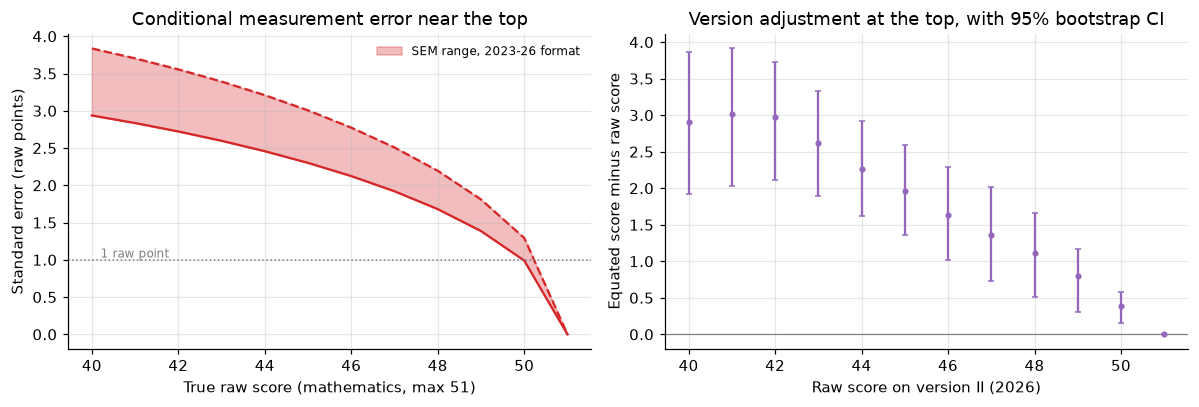

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.fill_between(sem.true_raw, sem.sem_lower, sem.sem_upper_2026fmt, alpha=0.3, color="tab:red",
                label="SEM range, 2023-26 format")
ax.plot(sem.true_raw, sem.sem_lower, color="tab:red")
ax.plot(sem.true_raw, sem.sem_upper_2026fmt, color="tab:red", ls="--")
ax.axhline(1, color="grey", ls=":", lw=1)
ax.text(40.2, 1.03, "1 raw point", fontsize=8, color="grey")
ax.set_xlabel("True raw score (mathematics, max 51)")
ax.set_ylabel("Standard error (raw points)")
ax.set_title("Conditional measurement error near the top")
ax.legend(fontsize=8, frameon=False)
ax = axes[1]
ax.errorbar(eqse.raw_v2, eqse.boot_mean - eqse.raw_v2, yerr=[eqse.boot_mean - eqse.ci95_lo, eqse.ci95_hi - eqse.boot_mean],
            fmt="o", ms=3, color="tab:purple", capsize=2)
ax.axhline(0, color="grey", lw=0.8)
ax.set_xlabel("Raw score on version II (2026)")
ax.set_ylabel("Equated score minus raw score")
ax.set_title("Version adjustment at the top, with 95% bootstrap CI")
fig.tight_layout()
savefig(fig, "fig03_measurement_error")